<a href="https://colab.research.google.com/github/shivakamibaiju-alt/ml_lab/blob/main/experiment8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix
)

In [2]:
# Load Fashion-MNIST dataset
(X_train_full, y_train_full), (X_test_full, y_test_full) = fashion_mnist.load_data()

# Class names
class_names = [
    'T-shirt/top',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle boot'
]

print(f"Full Training set shape: {X_train_full.shape}")
print(f"Full Test set shape: {X_test_full.shape}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Full Training set shape: (60000, 28, 28)
Full Test set shape: (10000, 28, 28)


In [3]:
# Select 10,000 training images using stratified sampling
_, X_train_sub, _, y_train_sub = train_test_split(
    X_train_full,
    y_train_full,
    test_size=10000,
    stratify=y_train_full,
    random_state=42
)

# Select 2,000 test images using stratified sampling
_, X_test_sub, _, y_test_sub = train_test_split(
    X_test_full,
    y_test_full,
    test_size=2000,
    stratify=y_test_full,
    random_state=42
)

# Flatten 28x28 images into 784-dimensional vectors
X_train_flat = X_train_sub.reshape(
    X_train_sub.shape[0], -1
)

X_test_flat = X_test_sub.reshape(
    X_test_sub.shape[0], -1
)

# Normalize pixel values from 0-255 to 0-1
X_train_norm = X_train_flat / 255.0
X_test_norm = X_test_flat / 255.0

print(f"Subsampled & Processed Training Shape: {X_train_norm.shape}")
print(f"Subsampled & Processed Testing Shape: {X_test_norm.shape}")

Subsampled & Processed Training Shape: (10000, 784)
Subsampled & Processed Testing Shape: (2000, 784)


In [4]:
# K values to evaluate
k_values = [1, 3, 5, 7, 9, 11, 15]

accuracies = []
inference_times = []

print("Starting KNN Experiments...\n")

for k in k_values:

    print(f"Evaluating K = {k}...")

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric='minkowski',
        p=2,
        n_jobs=-1
    )

    # Train model
    knn.fit(X_train_norm, y_train_sub)

    # Measure prediction time
    start_time = time.time()

    y_pred = knn.predict(X_test_norm)

    end_time = time.time()

    elapsed_time = end_time - start_time

    # Calculate accuracy
    acc = accuracy_score(y_test_sub, y_pred)

    accuracies.append(acc)
    inference_times.append(elapsed_time)

    print(
        f"-> Accuracy: {acc:.4f} | "
        f"Inference Time: {elapsed_time:.2f} seconds\n"
    )

Starting KNN Experiments...

Evaluating K = 1...
-> Accuracy: 0.8025 | Inference Time: 2.07 seconds

Evaluating K = 3...
-> Accuracy: 0.8110 | Inference Time: 1.32 seconds

Evaluating K = 5...
-> Accuracy: 0.8105 | Inference Time: 1.65 seconds

Evaluating K = 7...
-> Accuracy: 0.8070 | Inference Time: 1.54 seconds

Evaluating K = 9...
-> Accuracy: 0.8095 | Inference Time: 0.99 seconds

Evaluating K = 11...
-> Accuracy: 0.8065 | Inference Time: 0.81 seconds

Evaluating K = 15...
-> Accuracy: 0.8040 | Inference Time: 0.79 seconds



In [5]:
# Find K with highest accuracy
best_k_idx = np.argmax(accuracies)
best_k = k_values[best_k_idx]

print(f"Optimal configuration found at K = {best_k}")
print(f"Best Accuracy = {accuracies[best_k_idx]:.4f}")

Optimal configuration found at K = 3
Best Accuracy = 0.8110


In [6]:
# Train KNN using the best K
best_knn = KNeighborsClassifier(
    n_neighbors=best_k,
    metric='minkowski',
    p=2,
    n_jobs=-1
)

best_knn.fit(X_train_norm, y_train_sub)

# Predict test data
y_pred_best = best_knn.predict(X_test_norm)

# Classification report
print("\n### Classification Report ###")

print(
    classification_report(
        y_test_sub,
        y_pred_best,
        target_names=class_names
    )
)


### Classification Report ###
              precision    recall  f1-score   support

 T-shirt/top       0.72      0.84      0.78       200
     Trouser       0.98      0.97      0.98       200
    Pullover       0.60      0.77      0.67       200
       Dress       0.87      0.80      0.83       200
        Coat       0.71      0.65      0.68       200
      Sandal       0.99      0.81      0.89       200
       Shirt       0.56      0.46      0.51       200
     Sneaker       0.87      0.94      0.90       200
         Bag       0.98      0.91      0.94       200
  Ankle boot       0.88      0.97      0.92       200

    accuracy                           0.81      2000
   macro avg       0.82      0.81      0.81      2000
weighted avg       0.82      0.81      0.81      2000



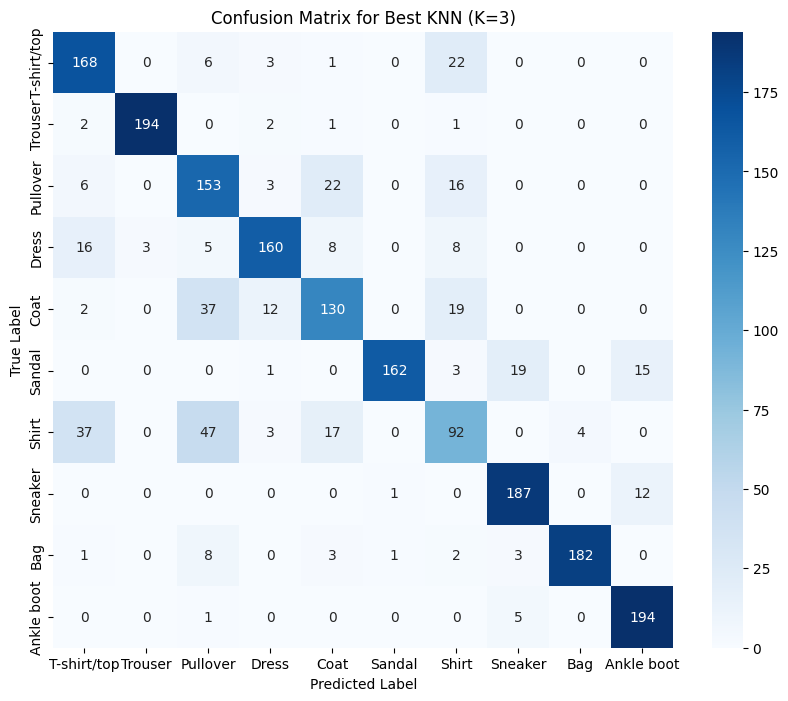

In [7]:
# Generate confusion matrix
cm = confusion_matrix(
    y_test_sub,
    y_pred_best
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    f'Confusion Matrix for Best KNN (K={best_k})'
)

plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

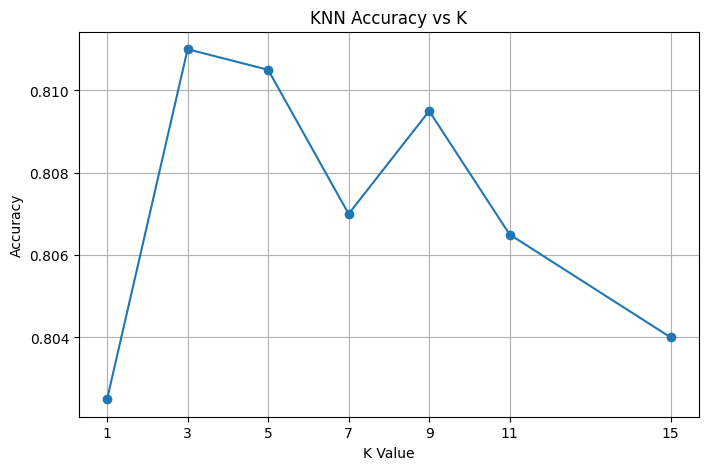

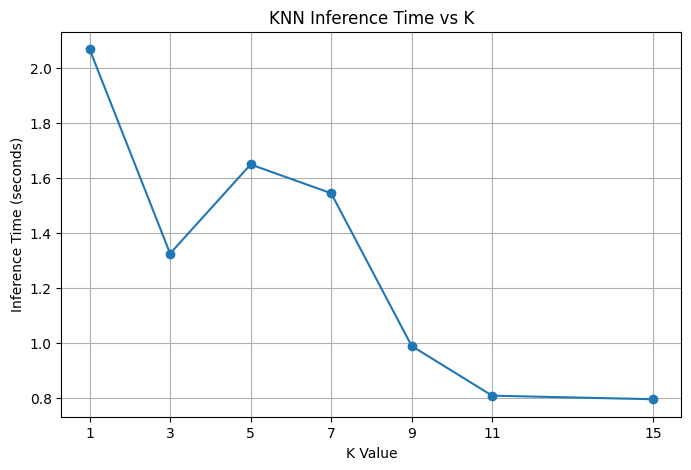

In [8]:
# Plot accuracy vs K

plt.figure(figsize=(8, 5))

plt.plot(k_values, accuracies, marker='o')

plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs K')

plt.xticks(k_values)
plt.grid(True)
plt.show()


# Plot inference time vs K

plt.figure(figsize=(8, 5))

plt.plot(k_values, inference_times, marker='o')

plt.xlabel('K Value')
plt.ylabel('Inference Time (seconds)')
plt.title('KNN Inference Time vs K')

plt.xticks(k_values)
plt.grid(True)
plt.show()